# IEEE 39 bus: native Simulink, DPsim ME, and DPsim CS

This notebook compares a single FMI 3 averaged inverter in a three-phase IEEE 39 bus EMT network. The FMU exposes both Model Exchange (ME) and Co-Simulation (CS) from the same source. Native Simulink executes the same current-control equations against each DPsim run's recorded inverter-terminal voltage.

The native runs are **open-loop component replays**, so they validate the inverter dynamics under an identical voltage input. The ME/CS comparison is closed-loop at the full DPsim network level. It does not claim a closed-loop native Simulink IEEE 39 network.

## Reproduce

From the repository root, run `python3 dpsim-fmi/examples/ieee39_inverter/run_ieee39_comparison.py --run` with MATLAB R2025a and Simulink available. This rebuilds the dual-interface FMU and runner, runs both DPsim cases, runs native Simulink replays, and refreshes the metrics and plots. Running this notebook only reloads existing outputs.

The case keeps the original IEEE 39 network and generator at bus 30 at half its original P/Q, while the inverter supplies the other half (125 MW, 80.881 Mvar). A 100 MW balanced load connects at bus 39 at 0.170 s. Runs span 0.2 s at 50 µs (4,000 network steps).

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

repo = Path.cwd()
if not (repo / 'dpsim-fmi/examples/ieee39_inverter/run_ieee39_comparison.py').exists():
    raise FileNotFoundError('Open this notebook with the DPsim repository as its working directory.')
case = repo / 'dpsim-fmi/examples/ieee39_inverter'
build = next((candidate for candidate in (repo / 'build-fmi-cosim', repo / 'build-fmi') if (candidate / 'CMakeCache.txt').is_file()), repo / 'build-fmi-cosim')
data = build / 'ieee39-inverter'
metrics = json.loads((data / 'ieee39_metrics.json').read_text())
timings = metrics['timings']

runtime_rows = [
    {'Execution': 'DPsim ME (SinglePassExplicit)', 'Runtime [s]': timings['me']['simulation_runtime_s'], 'Step [µs]': timings['me']['communication_step_s'] * 1e6, 'Steps': timings['me']['network_steps']},
    {'Execution': 'DPsim CS', 'Runtime [s]': timings['cs']['simulation_runtime_s'], 'Step [µs]': timings['cs']['communication_step_s'] * 1e6, 'Steps': timings['cs']['network_steps']},
    {'Execution': 'Native Simulink replay (ME trace)', 'Runtime [s]': timings['native_replay']['me']['runtime_s'], 'Step [µs]': timings['native_replay']['me']['fixed_step_s'] * 1e6, 'Steps': round(0.2 / timings['native_replay']['me']['fixed_step_s'])},
    {'Execution': 'Native Simulink replay (CS trace)', 'Runtime [s]': timings['native_replay']['cs']['runtime_s'], 'Step [µs]': timings['native_replay']['cs']['fixed_step_s'] * 1e6, 'Steps': round(0.2 / timings['native_replay']['cs']['fixed_step_s'])},
]
display(pd.DataFrame(runtime_rows).set_index('Execution').round(4))

,Runtime [s],Step [µs],Steps
Execution,,,
DPsim ME (SinglePassExplicit),1.3297,50.0,4000
DPsim CS,0.7539,50.0,4000
Native Simulink replay (ME trace),20.8102,1.0,200000
Native Simulink replay (CS trace),2.5521,1.0,200000


## Numerical comparison

Current errors compare each DPsim mode with the native Simulink replay driven by that same DPsim mode's terminal voltage, or compare CS directly with ME. Voltage errors compare closed-loop DPsim ME and CS at selected buses. Peak-base percentages use the appropriate nominal phase peak for current or voltage. The load-step window is 0.170–0.190 s.

In [2]:
post = 'post_startup'
rows = []
for key, label in [('me_vs_native_replay', 'ME vs native replay'), ('cs_vs_native_replay', 'CS vs native replay'), ('cs_vs_me', 'CS vs ME')]:
    m = metrics['current_error'][key][post]
    rows.append({'Comparison': label, 'Max error [A]': m['max_abs'], 'RMS error [A]': m['rms'], 'Max error [% current base]': m['max_abs_percent_base']})
for bus in ['30', '39']:
    m = metrics['bus_voltage_me_vs_cs'][bus][post]
    rows.append({'Comparison': f'CS vs ME, bus {bus} voltage', 'Max error [V]': m['max_abs'], 'RMS error [V]': m['rms'], 'Max error [% voltage base]': m['max_abs_percent_base']})
display(pd.DataFrame(rows).set_index('Comparison').round(6))

transient_rows = []
for key, label in [('me_vs_native_replay', 'ME vs native replay'), ('cs_vs_native_replay', 'CS vs native replay'), ('cs_vs_me', 'CS vs ME')]:
    m = metrics['current_error'][key]['load_step_window']
    transient_rows.append({'Comparison': label, 'Max current error [A]': m['max_abs'], 'RMS current error [A]': m['rms'], 'Max error [% current base]': m['max_abs_percent_base']})
for bus in ['30', '39']:
    m = metrics['bus_voltage_me_vs_cs'][bus]['load_step_window']
    transient_rows.append({'Comparison': f'CS vs ME, bus {bus} voltage', 'Max voltage error [V]': m['max_abs'], 'RMS voltage error [V]': m['rms'], 'Max error [% voltage base]': m['max_abs_percent_base']})
display(pd.DataFrame(transient_rows).set_index('Comparison').round(6))

,Max error [A],RMS error [A],Max error [% current base],Max error [V],RMS error [V],Max error [% voltage base]
Comparison,,,,,,
ME vs native replay,0.559922,0.047921,0.158906,NaN,NaN,NaN
CS vs native replay,1.616644,1.049286,0.458805,NaN,NaN,NaN
CS vs ME,1.493929,1.048794,0.423978,NaN,NaN,NaN
"CS vs ME, bus 30 voltage",NaN,NaN,NaN,0.330871,0.160805,0.000117
"CS vs ME, bus 39 voltage",NaN,NaN,NaN,0.025656,0.010326,0.000009


,Max current error [A],RMS current error [A],Max error [% current base],Max voltage error [V],RMS voltage error [V],Max error [% voltage base]
Comparison,,,,,,
ME vs native replay,0.008513,0.006019,0.002416,NaN,NaN,NaN
CS vs native replay,1.484807,1.049918,0.421390,NaN,NaN,NaN
CS vs ME,1.483012,1.048646,0.420880,NaN,NaN,NaN
"CS vs ME, bus 30 voltage",NaN,NaN,NaN,0.313056,0.212601,0.000111
"CS vs ME, bus 39 voltage",NaN,NaN,NaN,0.024373,0.015574,0.000009


Coupling diagnostics:
{
  "me_max_newton_iterations": 2,
  "me_mean_newton_iterations": 2.0,
  "me_max_reported_residual": 6.7e-05,
  "me_max_internal_steps_per_macro_step": 1,
  "cs_do_step_calls": 4000,
  "interpretation": "ME uses SinglePassExplicit as the network coupling policy; its residual is the one-pass mismatch, not a converged Newton residual. CS performs one fmi3DoStep per 50 us network step."
}
Waveforms:


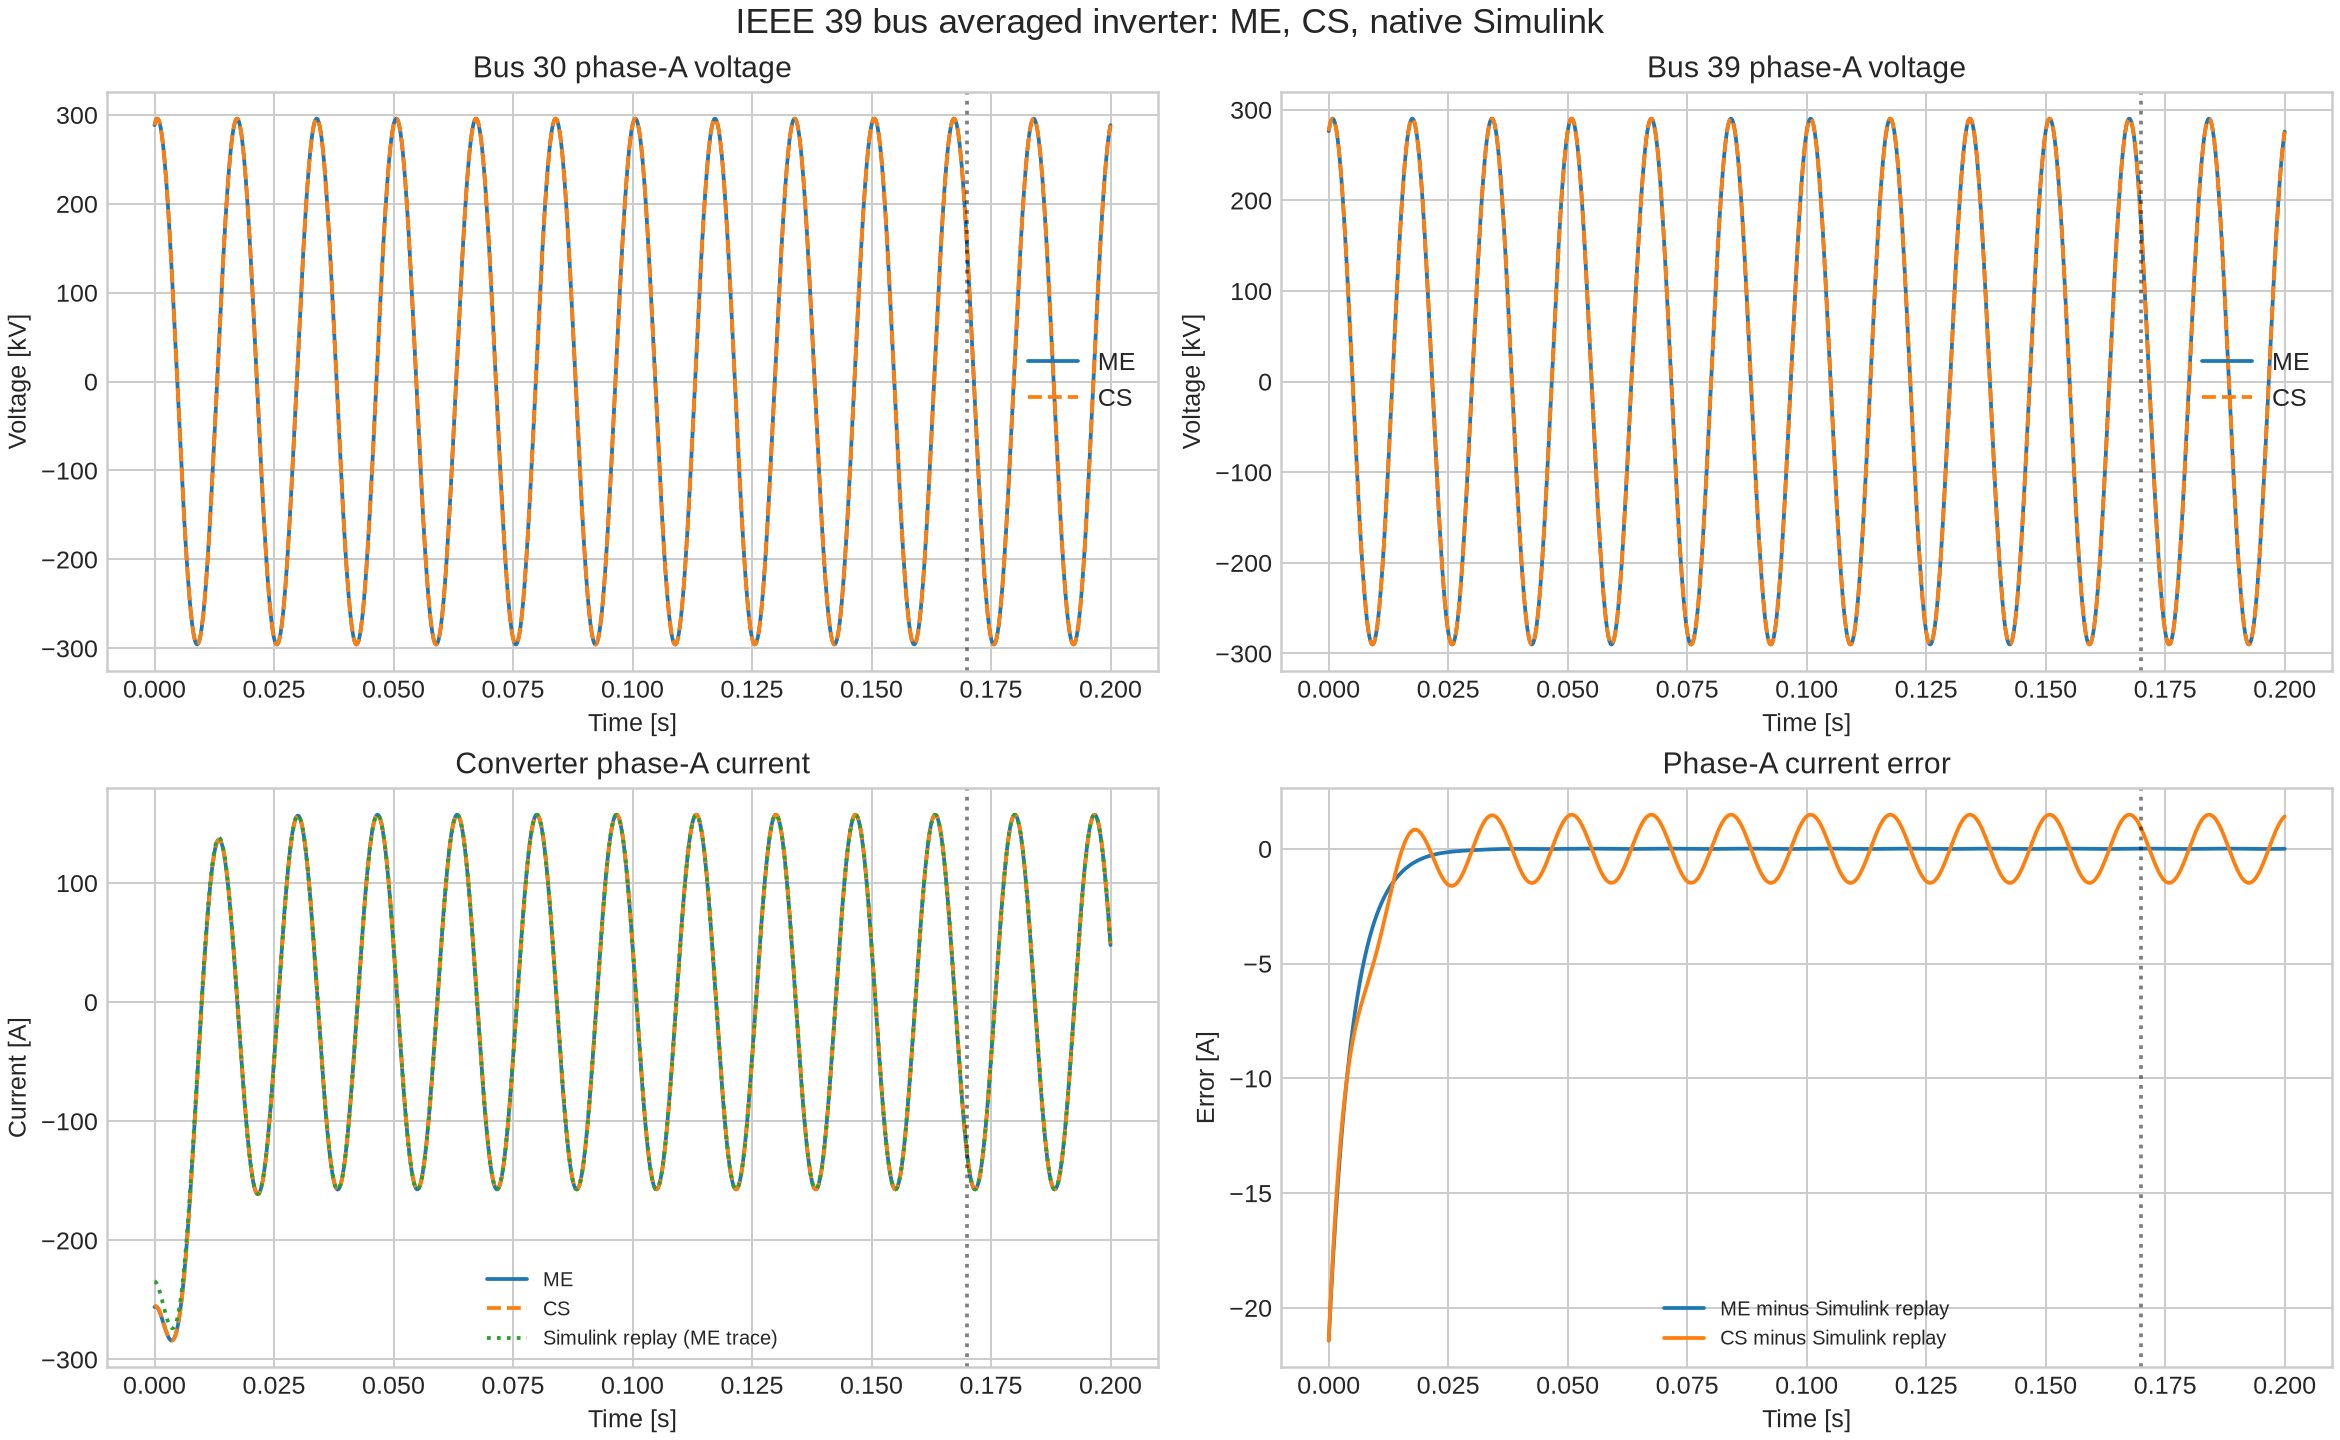

Errors and load-step detail:


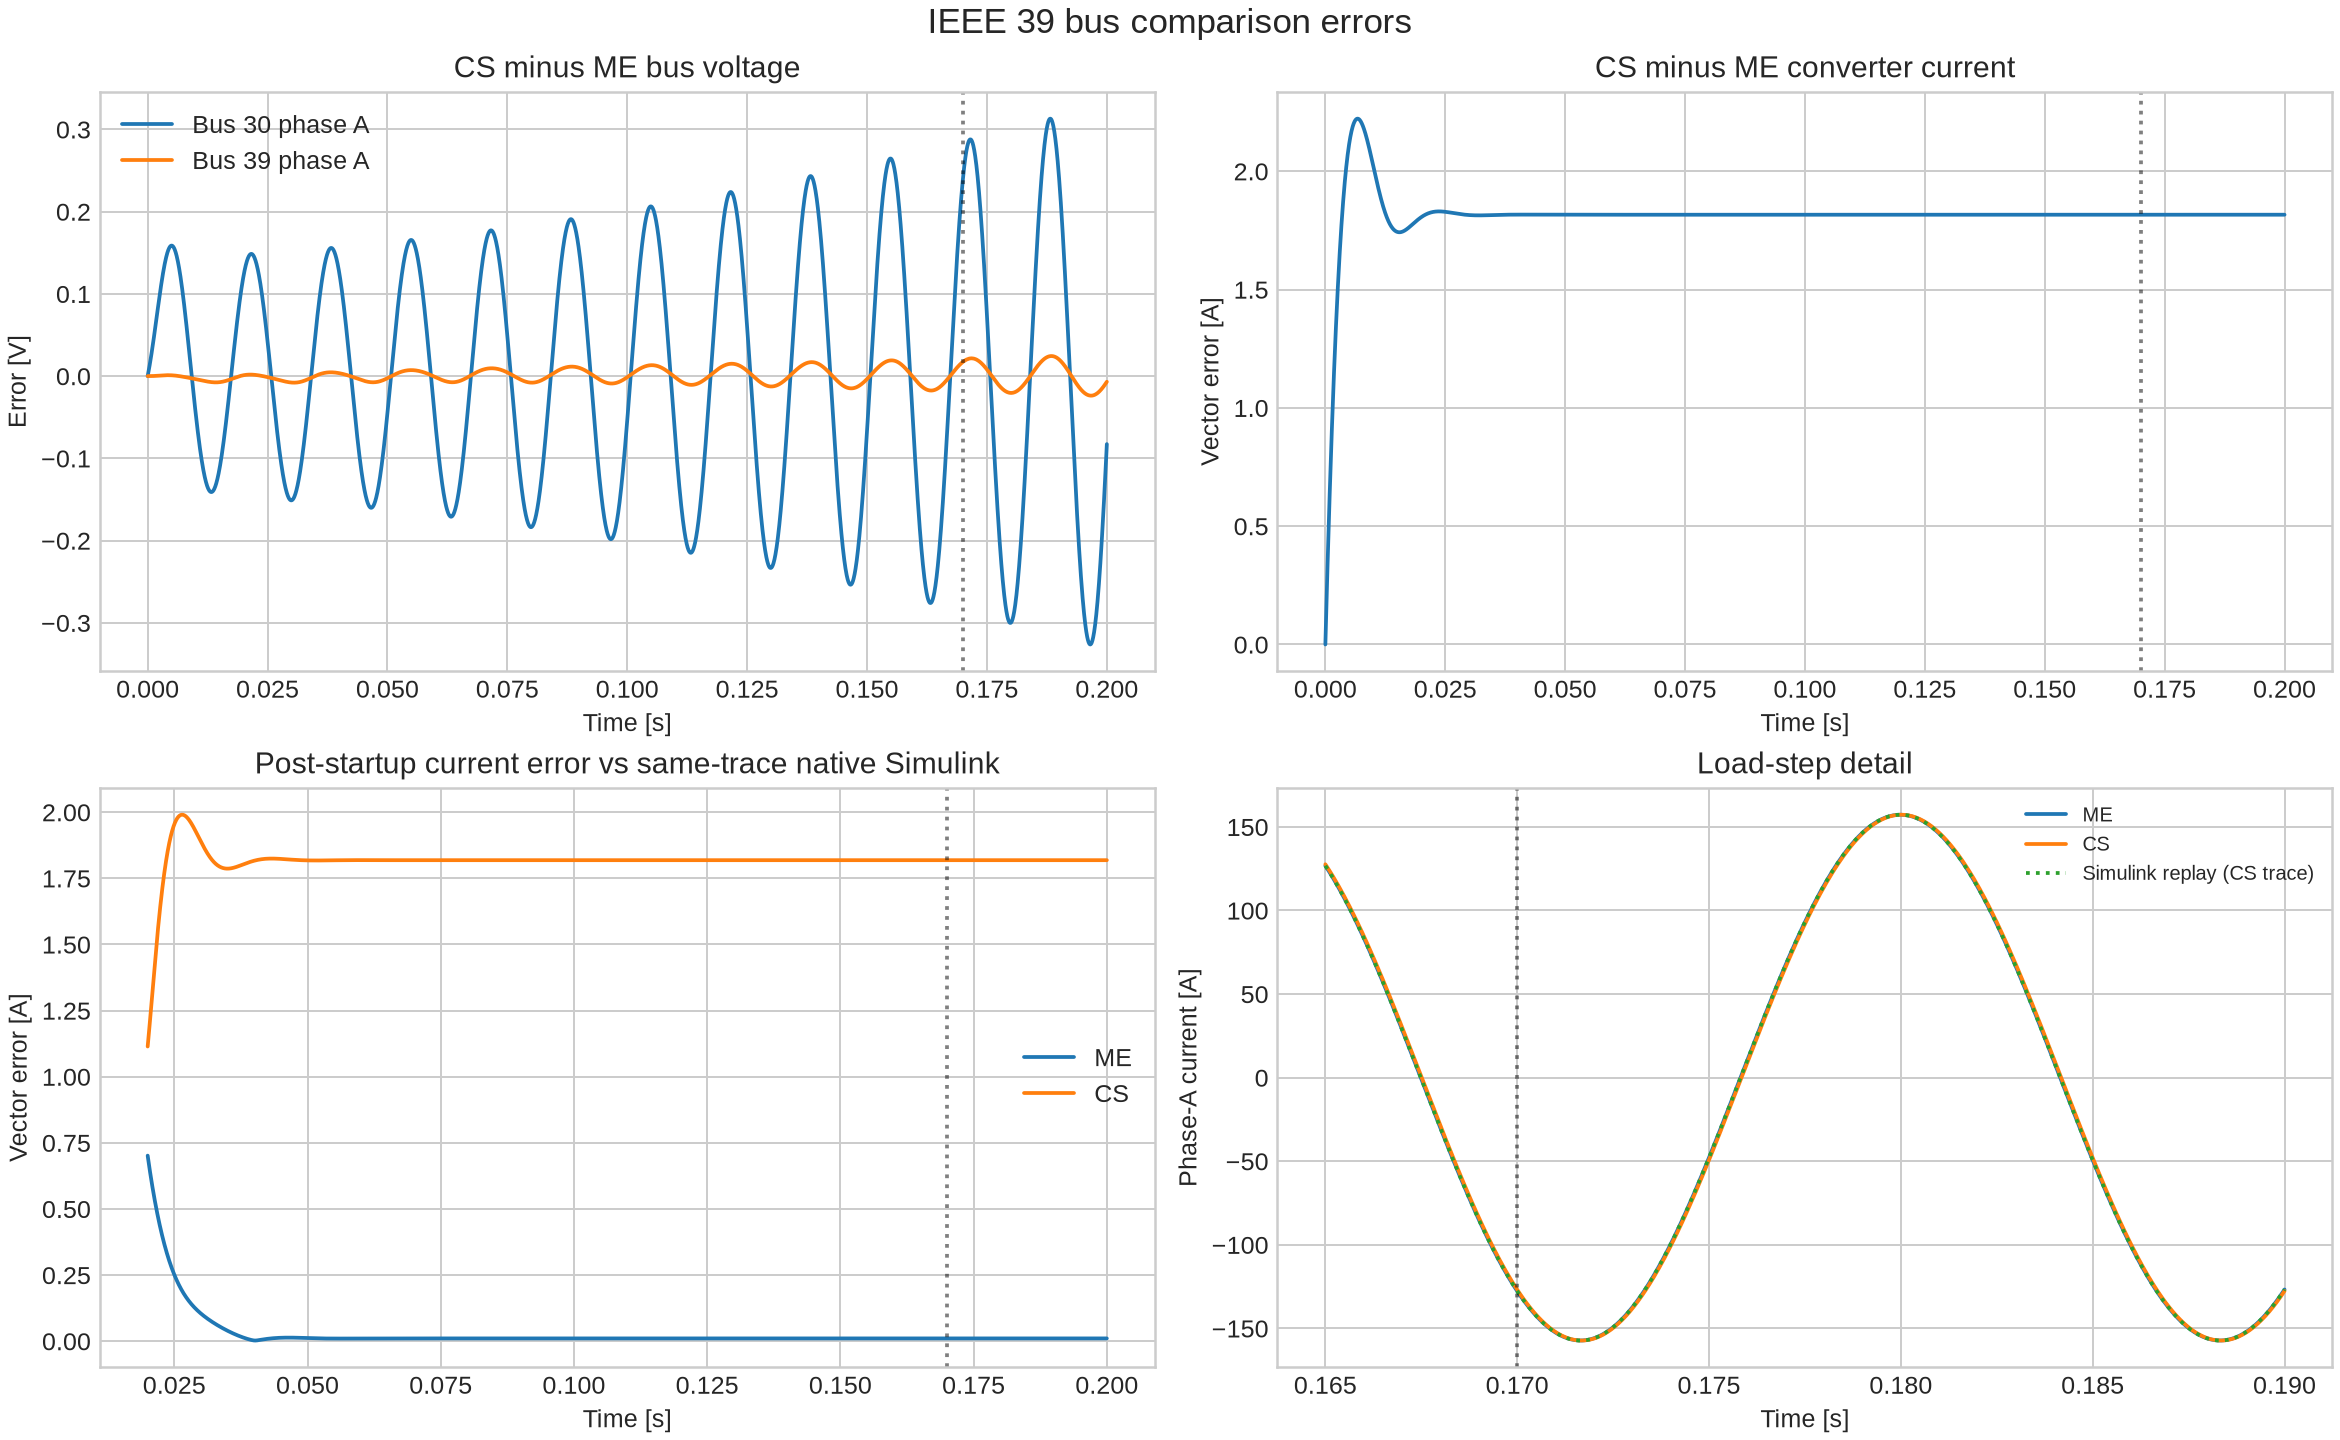

In [3]:
print('Coupling diagnostics:')
print(json.dumps(metrics['coupling_diagnostics'], indent=2))
print('Waveforms:')
display(Image(filename=str(data / 'ieee39_waveforms.png')))
print('Errors and load-step detail:')
display(Image(filename=str(data / 'ieee39_errors.png')))

## Interpretation and limits

- The same dual-interface averaged FMU and same grid are used for the DPsim ME and CS executions.
- ME uses `SinglePassExplicit`; the recorded ME residual is a one-pass coupling mismatch, not a converged Newton residual. CS makes one `fmi3DoStep` per 50 µs network step.
- Native Simulink traces use a 1 µs fixed-step RK4 replay and start from the matched current at the first terminal-voltage sample. These are component-level references, not a third closed-loop full-grid implementation.
- The originally switched MathWorks inverter export to FMI CS required an external execution tool and had no standalone binary. The runnable comparison therefore uses the self-contained averaged dual ME/CS FMU.
- Runtime values are environment-specific and include neither MATLAB startup nor FMU build time. Native replay time is the measured Simulink simulation time; the batch wall time also includes MATLAB startup and model handling.